# Course 13: Machine Learning for Agriculture and Climate
## Session 7: Machine learning weather prediction

**Goal:** simulate a chaotic toy atmosphere (Lorenz-96), train a small periodic CNN to step it forward 6 hours, roll it out to 25 days against persistence, climatology and a perfect model, and see how MSE training blurs long forecasts and how an ensemble measures its own uncertainty.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. A toy atmosphere: Lorenz-96
Real machine-learning weather models (GraphCast, Pangu-Weather, AIFS and others) learn a 6-hour step from about 40 years of ERA5 reanalysis, which is far too big for a laptop. Here the "true atmosphere" is the **Lorenz-96 model** (Lorenz 1996): 40 variables $x_1, \dots, x_{40}$ equally spaced around a latitude circle, with

$$\frac{dx_k}{dt} = (x_{k+1} - x_{k-2})\,x_{k-1} - x_k + F, \qquad F = 8,$$

and cyclic indices ($x_{41} = x_1$). The quadratic term moves "weather" around the circle, $-x_k$ is friction, and $F$ is the forcing. With $F = 8$ the system is chaotic. Lorenz scaled time so that one unit is about 5 days, so one step of 0.05 units is about **6 hours**, the step of most machine-learning weather models. We integrate it with the fourth-order Runge–Kutta method (RK4).

**All data in this notebook are synthetic.** The toy stands in for ERA5 (the training data) and for WeatherBench 2 (the evaluation data); section 7 shows how to load the real data.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

t_start = time.time()
torch.set_num_threads(1)
torch.manual_seed(0)
np.random.seed(0)

K, F = 40, 8.0              # 40 variables around a latitude circle, forcing F = 8
DT, SUB = 0.05, 5           # one model step = 0.05 time units (about 6 hours), done as 5 RK4 sub-steps
STEPS_PER_DAY = 4

def tendency(x):
    """dx_k/dt = (x_{k+1} - x_{k-2}) x_{k-1} - x_k + F, with cyclic indices; works on arrays [..., K]."""
    return (np.roll(x, -1, -1) - np.roll(x, 2, -1)) * np.roll(x, 1, -1) - x + F

def true_step(x):
    """Advance the 'true atmosphere' by one 6-hour step (fourth-order Runge-Kutta)."""
    h = DT / SUB
    for _ in range(SUB):
        k1 = tendency(x); k2 = tendency(x + h / 2 * k1); k3 = tendency(x + h / 2 * k2); k4 = tendency(x + h * k3)
        x = x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return x

def trajectory(x, n_steps, step=true_step):
    out = np.empty((n_steps + 1,) + x.shape); out[0] = x
    for i in range(n_steps):
        x = step(x); out[i + 1] = x
    return out

rng = np.random.default_rng(0)
def random_states(n):
    """n independent states on the attractor: start near the rest state x = F and spin up for 50 days."""
    return trajectory(F + 0.01 * rng.standard_normal((n, K)), 200)[-1]

train = trajectory(random_states(100), 200)    # [time, run, K]: 100 runs of 200 steps (50 days each)
test = trajectory(random_states(200), 100)     # 200 independent test cases, each followed for 100 steps (25 days)
clim_mean, clim_std = train.mean(), train.std()
n_pairs = train.shape[1] * (train.shape[0] - 1)
print(f"training data: {n_pairs:,} pairs (x(t), x(t + 6 h)), about {n_pairs / STEPS_PER_DAY / 365:.1f} years of 6-hourly states")
print(f"climatology: mean {clim_mean:.3f}, standard deviation {clim_std:.3f}; "
      f"6-hour change: standard deviation {np.diff(train, axis=0).std():.3f}")
print(f"test data: {test.shape[1]} cases x {test.shape[0] - 1} steps ({(test.shape[0] - 1) // STEPS_PER_DAY} days)")

training data: 20,000 pairs (x(t), x(t + 6 h)), about 13.7 years of 6-hourly states
climatology: mean 2.347, standard deviation 3.644; 6-hour change: standard deviation 0.925
test data: 200 cases x 100 steps (25 days)


### 2. The predictability limit: a perfect model with a small initial error
Even a perfect model fails eventually, because we never know the initial state exactly. Forecast centres estimate it by **data assimilation**, which combines observations with a short forecast to give the **analysis**, and the analysis has errors. In a chaotic system a small error grows roughly exponentially until it is as large as the differences between two random states: then the RMSE saturates at $\sqrt{2}$ times the climate standard deviation. The **climatology forecast** (always predict the long-term mean) has RMSE equal to the climate standard deviation, so a forecast whose RMSE is above that is worse than climatology.

We run the true model from analyses with four sizes of initial error and find the day each forecast becomes worse than climatology.

In [2]:
def rmse_by_lead(forecast, truth):
    """forecast, truth: [lead, case, K] -> RMSE over cases and variables at each lead."""
    return np.sqrt(((forecast - truth) ** 2).mean(axis=(1, 2)))

def first_crossing(curve, level):
    """First lead (in days) at which curve > level, as text."""
    above = np.nonzero(curve > level)[0]
    return f"from day {above[0] / STEPS_PER_DAY:.2f}" if len(above) else f"never within {n_lead // STEPS_PER_DAY} days"

n_lead = test.shape[0] - 1
days = np.arange(n_lead + 1) / STEPS_PER_DAY
clim_rmse = np.sqrt(((test - clim_mean) ** 2).mean(axis=(1, 2)))       # forecast = the climatological mean
clim_level = clim_rmse.mean()
perfect, analyses = {}, {}
for sigma0 in [1.0, 0.1, 0.01, 0.001]:
    analyses[sigma0] = test[0] + sigma0 * rng.standard_normal(test[0].shape)     # the analysis: truth + error
    perfect[sigma0] = rmse_by_lead(trajectory(analyses[sigma0], n_lead), test)
    print(f"perfect model, initial error {sigma0:5.3f}: RMSE at day 5 {perfect[sigma0][5 * STEPS_PER_DAY]:.3f}; "
          f"worse than climatology (RMSE {clim_level:.2f}) {first_crossing(perfect[sigma0], clim_level)}")
small = slice(1 * STEPS_PER_DAY, 8 * STEPS_PER_DAY + 1)                 # days 1-8, while the 0.001 error is still small
rate = np.polyfit(days[small], np.log(perfect[0.001][small]), 1)[0]
print(f"while the error is small it grows x{np.exp(rate):.2f} per day: doubling time {np.log(2) / rate:.2f} days")
print(f"saturation level sqrt(2) x climate std = {np.sqrt(2) * clim_std:.2f}")

perfect model, initial error 1.000: RMSE at day 5 3.699; worse than climatology (RMSE 3.64) from day 5.00


perfect model, initial error 0.100: RMSE at day 5 0.726; worse than climatology (RMSE 3.64) from day 13.50
perfect model, initial error 0.010: RMSE at day 5 0.107; worse than climatology (RMSE 3.64) from day 20.25


perfect model, initial error 0.001: RMSE at day 5 0.009; worse than climatology (RMSE 3.64) never within 25 days
while the error is small it grows x1.59 per day: doubling time 1.50 days
saturation level sqrt(2) x climate std = 5.15


### 3. A learned 6-hour step: a small periodic CNN
The network sees the 40 values at time $t$ and predicts the **change** over the next 6 hours, $x(t + 6\,\text{h}) - x(t)$, as most machine-learning weather models do. Circular padding makes the convolution wrap around the latitude circle, and because the same weights are used at every position the network treats every longitude alike. GraphCast does the same kind of thing with message passing on a mesh around the globe (Course 7 session 11). Training minimizes the mean squared error (MSE) of the change, on 20,000 pairs.

In [3]:
class StepCNN(nn.Module):
    """x(t) -> x(t + 6 h) - x(t), with circular padding because the 40 variables lie on a circle."""
    def __init__(self, ch=32):
        super().__init__()
        self.c1 = nn.Conv1d(1, ch, 5, padding=2, padding_mode="circular")
        self.c2 = nn.Conv1d(ch, ch, 3, padding=1, padding_mode="circular")
        self.c3 = nn.Conv1d(ch, 1, 1)
    def forward(self, x):
        h = torch.tanh(self.c1(x[:, None]))
        return self.c3(torch.tanh(self.c2(h)))[:, 0]

def fit(net, Xt, Yt, epochs, batch=256, lr=3e-3, noise=0.0, seed=0):
    """Adam with a one-cycle learning-rate schedule; optional Gaussian noise added to the inputs."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(net.parameters(), lr)
    n_batches = len(Xt) // batch
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * n_batches)
    for ep in range(epochs):
        perm = torch.randperm(len(Xt), generator=g)
        for b in range(n_batches):
            idx = perm[b * batch:(b + 1) * batch]
            xin = Xt[idx] + noise * torch.randn(len(idx), Xt.shape[1], generator=g)
            loss = ((net(xin) - Yt[idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return net

X, Y = train[:-1].reshape(-1, K), train[1:].reshape(-1, K)
inc_std = (Y - X).std()
t0 = time.time()
torch.manual_seed(0)
step_net = fit(StepCNN(), torch.tensor((X - clim_mean) / clim_std, dtype=torch.float32),
               torch.tensor((Y - X) / inc_std, dtype=torch.float32), epochs=25)
print(f"step CNN: {sum(p.numel() for p in step_net.parameters()):,} parameters, trained in {time.time() - t0:.0f} s")

def ml_step(x):
    """One 6-hour step of the learned model (works on arrays [..., K])."""
    with torch.no_grad():
        dx = step_net(torch.tensor((x.reshape(-1, K) - clim_mean) / clim_std, dtype=torch.float32)).numpy()
    return x + inc_std * dx.reshape(x.shape)

print(f"one-step (6-hour) test RMSE: CNN {np.sqrt(((ml_step(test[0]) - test[1]) ** 2).mean()):.4f}, "
      f"persistence {np.sqrt(((test[0] - test[1]) ** 2).mean()):.4f}")

step CNN: 3,329 parameters, trained in 16 s
one-step (6-hour) test RMSE: CNN 0.0493, persistence 0.9312


### 4. Rolling the model out to 25 days
A 10-day forecast is the learned step applied 40 times, each time to the model's own output (an **autoregressive rollout**). Every forecast below starts from the same analysis, with initial error 0.1 (about 3% of the climate standard deviation). We compare four forecasts:

* the **CNN rollout**;
* the **perfect model** (the true equations) from the same analysis: the best any model could do;
* **persistence**: tomorrow is like today;
* **climatology**: always the long-term mean.

We also compute the **anomaly correlation** (ACC; session 6): the correlation between forecast and true departures from climatology.

RMSE at lead (days)        1      3      5      7     10     15     20
CNN rollout            0.220  0.622  1.332  2.314  3.380  4.504  4.934
perfect model          0.134  0.327  0.726  1.455  2.637  4.089  4.766
persistence            3.281  5.420  5.482  4.882  5.145  5.056  5.190
climatology            3.622  3.603  3.646  3.645  3.650  3.642  3.658
CNN rollout: worse than climatology from day 11.00
perfect model: worse than climatology from day 13.50
persistence: worse than climatology from day 1.25
anomaly correlation below 0.6 from day 9.75 (CNN) and from day 12.00 (perfect model)


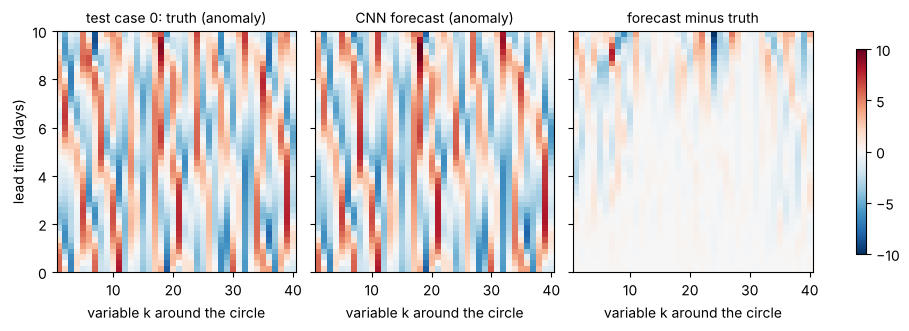

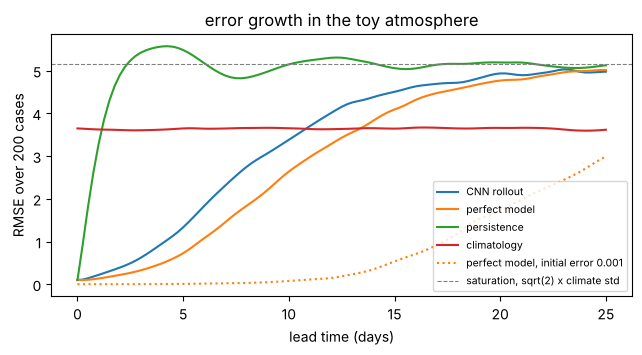

In [4]:
sigma_a = 0.1                                                         # analysis error, used from here on
analysis = analyses[sigma_a]                                          # the same analysis as in section 2
ml_run = trajectory(analysis, n_lead, step=ml_step)
pm_run = trajectory(analysis, n_lead)
persist = np.broadcast_to(analysis, test.shape)

def acc_by_lead(forecast, truth):
    fa, ta = forecast - clim_mean, truth - clim_mean                  # anomalies from climatology
    return (fa * ta).sum(axis=(1, 2)) / np.sqrt((fa ** 2).sum(axis=(1, 2)) * (ta ** 2).sum(axis=(1, 2)))

curves = {"CNN rollout": rmse_by_lead(ml_run, test), "perfect model": rmse_by_lead(pm_run, test),
          "persistence": rmse_by_lead(persist, test), "climatology": clim_rmse}
show = [1, 3, 5, 7, 10, 15, 20]
print("RMSE at lead (days)  " + "".join(f"{d:7d}" for d in show))
for name, c in curves.items():
    print(f"{name:20s} " + "".join(f"{c[d * STEPS_PER_DAY]:7.3f}" for d in show))
for name in ["CNN rollout", "perfect model", "persistence"]:
    print(f"{name}: worse than climatology {first_crossing(curves[name], clim_level)}")
acc_ml, acc_pm = acc_by_lead(ml_run, test), acc_by_lead(pm_run, test)
print(f"anomaly correlation below 0.6 {first_crossing(-acc_ml, -0.6)} (CNN) "
      f"and {first_crossing(-acc_pm, -0.6)} (perfect model)")

n10 = 10 * STEPS_PER_DAY
fig, ax = plt.subplots(1, 3, figsize=(9, 3.2), sharey=True, constrained_layout=True)
for a, field, title in zip(ax, [test[:n10 + 1, 0] - clim_mean, ml_run[:n10 + 1, 0] - clim_mean, ml_run[:n10 + 1, 0] - test[:n10 + 1, 0]],
                           ["test case 0: truth (anomaly)", "CNN forecast (anomaly)", "forecast minus truth"]):
    im = a.imshow(field, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-10, vmax=10, extent=[0.5, K + 0.5, 0, 10])
    a.set_title(title, fontsize=10); a.set_xlabel("variable k around the circle")
ax[0].set_ylabel("lead time (days)")
fig.colorbar(im, ax=list(ax), shrink=0.85)
plt.show()

plt.figure(figsize=(7.5, 3.4))
for name, c in curves.items():
    plt.plot(days, c, label=name)
plt.plot(days, perfect[0.001], ":", color="C1", label="perfect model, initial error 0.001")
plt.axhline(np.sqrt(2) * clim_std, color="gray", lw=0.8, ls="--", label="saturation, sqrt(2) x climate std")
plt.xlabel("lead time (days)"); plt.ylabel("RMSE over 200 cases"); plt.title("error growth in the toy atmosphere")
plt.legend(fontsize=7.5, loc="lower right"); plt.show()

### 5. Why MSE training blurs long forecasts
When the future is uncertain, the forecast that minimizes the expected squared error is the **average of the possible futures**, and an average of many different weather patterns is smooth and weak. So a network trained with MSE to predict far ahead learns to blur. GraphCast is trained with MSE on rollouts of up to 3 days, and its long-range forecasts are smoother than real weather.

To see this, we train a second CNN with MSE to predict 1, 3, 5, 7, 10 and 15 days ahead **in one shot** from the analysis (noise of size 0.1 is added to its training inputs, as analyses have errors). We measure each forecast's **activity**: the standard deviation of its departures from climatology. Real weather keeps an activity of about 3.6 at every lead; a blurred forecast has less.

In [5]:
leads_d = [1, 3, 5, 7, 10, 15]
lead_steps = [d * STEPS_PER_DAY for d in leads_d]
L = max(lead_steps)
Xd = train[:-L].reshape(-1, K)
Yd = np.stack([train[l:train.shape[0] - L + l].reshape(-1, K) for l in lead_steps], axis=1)   # [sample, lead, K]

class DirectCNN(nn.Module):
    """x(t) -> x(t + 1, 3, 5, 7, 10, 15 days) in one shot; dilated convolutions see the whole circle."""
    def __init__(self, ch=24, n_out=6):
        super().__init__()
        self.convs = nn.ModuleList([nn.Conv1d(1 if i == 0 else ch, ch, 5, padding=2 * d, dilation=d, padding_mode="circular")
                                    for i, d in enumerate([1, 2, 4, 8])])
        self.out = nn.Conv1d(ch, n_out, 1)
    def forward(self, x):
        h = x[:, None]
        for conv in self.convs:
            h = torch.tanh(conv(h))
        return self.out(h)

t0 = time.time()
torch.manual_seed(1)
direct_net = fit(DirectCNN(), torch.tensor((Xd - clim_mean) / clim_std, dtype=torch.float32),
                 torch.tensor((Yd - clim_mean) / clim_std, dtype=torch.float32), epochs=12,
                 noise=sigma_a / clim_std, seed=1)
with torch.no_grad():
    direct = direct_net(torch.tensor((analysis - clim_mean) / clim_std, dtype=torch.float32)).numpy() * clim_std + clim_mean
print(f"direct CNN: {sum(p.numel() for p in direct_net.parameters()):,} parameters, trained in {time.time() - t0:.0f} s")

activity = lambda f: (f - clim_mean).std()     # strength of the forecast's departures from climatology
print("lead (days) | RMSE: CNN rollout  direct MSE CNN | activity: truth  CNN rollout  direct MSE CNN")
for j, (d, l) in enumerate(zip(leads_d, lead_steps)):
    print(f"{d:11d} |      {curves['CNN rollout'][l]:6.3f}        {np.sqrt(((direct[:, j] - test[l]) ** 2).mean()):6.3f}"
          f"   |      {activity(test[l]):5.2f}     {activity(ml_run[l]):5.2f}          {activity(direct[:, j]):5.2f}")

direct CNN: 9,006 parameters, trained in 19 s
lead (days) | RMSE: CNN rollout  direct MSE CNN | activity: truth  CNN rollout  direct MSE CNN
          1 |       0.220         0.716   |       3.62      3.62           3.54
          3 |       0.622         2.392   |       3.60      3.61           2.71
          5 |       1.332         2.967   |       3.65      3.64           2.12
          7 |       2.314         3.270   |       3.64      3.64           1.64
         10 |       3.380         3.446   |       3.65      3.64           1.24
         15 |       4.504         3.558   |       3.64      3.61           0.84


### 6. An ensemble from perturbed initial conditions
Instead of one forecast, run 20: each starts from the analysis plus a new random perturbation of the same size as the analysis error (0.1). The **ensemble mean** estimates the average future, and the **spread** (the standard deviation of the members around their mean) estimates how uncertain the forecast is. In a reliable ensemble the spread matches the RMSE of the ensemble mean (with 20 members the expected ratio is $\sqrt{20/21} \approx 0.98$). We build the ensemble with the CNN and with the perfect model, and score it with the CRPS (session 6), here computed from the members as $\overline{|X - y|} - \tfrac12\,\overline{|X - X'|}$; for a single forecast the CRPS is its mean absolute error.

lead (days) | CNN ensemble: spread  error of mean  ratio | perfect-model ensemble: spread  error of mean  ratio
          1 |                0.135      0.222      0.61 |                          0.136      0.138      0.98
          3 |                0.344      0.623      0.55 |                          0.352      0.335      1.05
          5 |                0.740      1.288      0.57 |                          0.759      0.720      1.05
          7 |                1.302      2.118      0.61 |                          1.328      1.321      1.01
         10 |                2.116      2.867      0.74 |                          2.155      2.167      0.99
day 5 RMSE: single CNN forecast 1.332, CNN ensemble mean 1.288
day 5 CRPS: single CNN forecast 0.859, CNN ensemble 0.648, perfect-model ensemble 0.296
day 7 activity: truth 3.64, one CNN member 3.63, CNN ensemble mean 3.40, direct MSE CNN 1.64


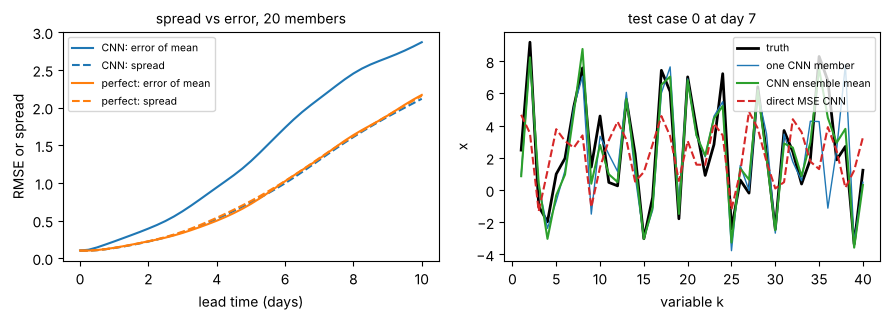

runtime so far 44 s


In [6]:
M = 20
pert = analysis[None] + sigma_a * np.random.default_rng(2).standard_normal((M,) + analysis.shape)   # [member, case, K]
ens_ml = trajectory(pert, n10, step=ml_step)          # [lead, member, case, K]
ens_pm = trajectory(pert, n10)
truth10 = test[:n10 + 1]

def spread_and_error(ens, truth):
    mean = ens.mean(axis=1)
    return mean, np.sqrt(ens.var(axis=1, ddof=1).mean(axis=(1, 2))), rmse_by_lead(mean, truth)

def crps_members(ens, y):
    """CRPS from M members (axis 0), averaged over cases and variables: mean|X - y| - 0.5 mean|X - X'|."""
    m = ens.shape[0]
    return (np.abs(ens - y).mean(axis=0) - 0.5 * np.abs(ens[:, None] - ens[None]).sum(axis=(0, 1)) / (m * (m - 1))).mean()

mean_ml, spread_ml, err_ml = spread_and_error(ens_ml, truth10)
mean_pm, spread_pm, err_pm = spread_and_error(ens_pm, truth10)
print("lead (days) | CNN ensemble: spread  error of mean  ratio | perfect-model ensemble: spread  error of mean  ratio")
for d in [1, 3, 5, 7, 10]:
    l = d * STEPS_PER_DAY
    print(f"{d:11d} |               {spread_ml[l]:6.3f}     {err_ml[l]:6.3f}     {spread_ml[l] / err_ml[l]:5.2f} |"
          f"                         {spread_pm[l]:6.3f}     {err_pm[l]:6.3f}     {spread_pm[l] / err_pm[l]:5.2f}")
l5, l7 = 5 * STEPS_PER_DAY, 7 * STEPS_PER_DAY
print(f"day 5 RMSE: single CNN forecast {curves['CNN rollout'][l5]:.3f}, CNN ensemble mean {err_ml[l5]:.3f}")
print(f"day 5 CRPS: single CNN forecast {np.abs(ml_run[l5] - test[l5]).mean():.3f}, CNN ensemble {crps_members(ens_ml[l5], test[l5]):.3f}, "
      f"perfect-model ensemble {crps_members(ens_pm[l5], test[l5]):.3f}")
print(f"day 7 activity: truth {activity(test[l7]):.2f}, one CNN member {activity(ens_ml[l7, 0]):.2f}, "
      f"CNN ensemble mean {activity(mean_ml[l7]):.2f}, direct MSE CNN {activity(direct[:, 3]):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
d10 = days[:n10 + 1]
ax[0].plot(d10, err_ml, "C0", label="CNN: error of mean"); ax[0].plot(d10, spread_ml, "C0--", label="CNN: spread")
ax[0].plot(d10, err_pm, "C1", label="perfect: error of mean"); ax[0].plot(d10, spread_pm, "C1--", label="perfect: spread")
ax[0].set_xlabel("lead time (days)"); ax[0].set_ylabel("RMSE or spread"); ax[0].set_title("spread vs error, 20 members", fontsize=10)
ax[0].legend(fontsize=7.5)
k = np.arange(1, K + 1)
ax[1].plot(k, test[l7, 0], "k", lw=2, label="truth")
ax[1].plot(k, ens_ml[l7, 0, 0], "C0", lw=1, label="one CNN member")
ax[1].plot(k, mean_ml[l7, 0], "C2", label="CNN ensemble mean")
ax[1].plot(k, direct[0, 3], "C3--", label="direct MSE CNN")
ax[1].set_xlabel("variable k"); ax[1].set_ylabel("x"); ax[1].set_title("test case 0 at day 7", fontsize=10)
ax[1].legend(fontsize=7.5)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 7. Real data (NOT RUN here)
The first cell reads ERA5 from the public WeatherBench 2 bucket on a coarse 64 × 32 grid (5.625°) and scores persistence and climatology for the 500 hPa geopotential (Z500), the field used in most headline scores, at leads of 1–10 days. The second downloads the latest forecast of ECMWF's operational data-driven model, AIFS Single, which ECMWF publishes as open data, and prints the 2-metre temperature at the grid point nearest Dhaka. Both need extra libraries and internet access.

In [ ]:
# NOT RUN: needs xarray, zarr and gcsfs (pip install xarray zarr gcsfs) and internet access to the public WeatherBench 2 bucket
import xarray as xr

era5 = xr.open_zarr("gs://weatherbench2/datasets/era5/1959-2022-6h-64x32_equiangular_conservative.zarr",
                    storage_options={"token": "anon"})
clim = xr.open_zarr("gs://weatherbench2/datasets/era5-hourly-climatology/1990-2019_6h_64x32_equiangular_conservative.zarr",
                    storage_options={"token": "anon"})
z500 = era5["geopotential"].sel(level=500, time=slice("2020-01-01", "2020-12-31")).load()   # m^2/s^2, 6-hourly
weights = np.cos(np.deg2rad(z500.latitude))                                               # grid boxes shrink towards the poles
for lead_days in [1, 3, 5, 10]:
    k = 4 * lead_days                                                                       # 6-hourly steps
    truth = z500.isel(time=slice(k, None))
    persistence = z500.isel(time=slice(None, -k)).assign_coords(time=truth.time)
    climatology = clim["geopotential"].sel(level=500).sel(dayofyear=truth.time.dt.dayofyear, hour=truth.time.dt.hour)
    for name, fc in [("persistence", persistence), ("climatology", climatology)]:
        mse = ((fc - truth) ** 2).weighted(weights).mean(("latitude", "longitude")).mean("time")
        print(f"Z500, lead {lead_days:2d} days, {name}: RMSE {float(np.sqrt(mse)):.0f} m^2/s^2")

In [ ]:
# NOT RUN: needs ecmwf-opendata, xarray and cfgrib (pip install ecmwf-opendata xarray cfgrib) and internet access
from ecmwf.opendata import Client
import xarray as xr

client = Client(source="ecmwf", model="aifs-single")      # ECMWF's data-driven model; model="ifs" gives the physics-based one
client.retrieve(type="fc", param="2t", step=list(range(0, 168, 6)), target="aifs_2t.grib2")   # latest run, 6-hourly to 7 days
ds = xr.open_dataset("aifs_2t.grib2", engine="cfgrib")
dhaka = ds["t2m"].sel(latitude=23.75, longitude=90.5, method="nearest") - 273.15          # kelvin to degrees Celsius
print("AIFS 2-metre temperature near Dhaka, every 6 hours (deg C):", np.round(dhaka.values, 1))

### 8. Exercises

In [7]:
# TODO: rollout training, as in GraphCast. Fine-tune a copy of step_net (copy.deepcopy) for a few epochs with a loss
# summed over 4 autoregressive steps (1 day): start from x(t), apply the network 4 times to its own output, and compare
# each step with x(t+1), ..., x(t+4) from `train`. Then roll it out from `analysis` and compare its day-5 RMSE and its
# day-10 activity with those of step_net. Does the rollout loss reduce the error? Does it make the forecast smoother?
def finetune_rollout(n_roll=4, epochs=3):
    return None          # replace with your code; return the fine-tuned network

r = finetune_rollout()
print("not done yet" if r is None else "fine-tuned: now roll it out and compare")

not done yet


In [8]:
# TODO: ensemble size. Rebuild the CNN ensemble with M = 5 and M = 50 members (keep sigma_a = 0.1) and report the
# day-5 RMSE of the ensemble mean and the day-5 CRPS for M = 5, 20 and 50. Which score improves more with more members?
def ensemble_size_study(sizes=(5, 20, 50)):
    return None          # replace with your code; return {M: (rmse_of_mean, crps)}

r = ensemble_size_study()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **Chaos limits even a perfect model.** With the true equations, an initial error of 1.0 made the forecast worse than climatology (RMSE 3.64) from day 5.00, an error of 0.1 from day 13.50 and an error of 0.01 from day 20.25; with 0.001 it stayed better for all 25 days. While small, the error grew 1.59 times per day (doubling every 1.50 days), so each tenfold cut in the initial error bought only about a week (8.5 and then 6.75 days here). Better observations and data assimilation help, but slowly.
2. **A very accurate step still drifts.** The 3,329-parameter CNN had a 6-hour RMSE of 0.0493 (persistence 0.9312). Rolled out from the same analysis, its RMSE was 0.220 at day 1, 1.332 at day 5 and 3.380 at day 10, against 0.134, 0.726 and 2.637 for the perfect model. It became worse than climatology from day 11.00 (perfect model 13.50, persistence 1.25), and its anomaly correlation fell below 0.6 from day 9.75 (perfect model 12.00). Model error cost about two days of useful forecast here.
3. **MSE training blurs, and RMSE rewards the blur only late.** The direct CNN trained with MSE kept an activity of 3.54 at day 1, but only 2.12 at day 5, 1.24 at day 10 and 0.84 at day 15, while the truth and the rollout stayed near 3.6. Against our first expectation, the blurred forecast was not better on RMSE at short leads: up to day 10 it was worse than the rollout (2.967 against 1.332 at day 5), because a small network cannot learn a 5-day jump. Only at day 15, beyond the useful range, did it win on RMSE: 3.558 against 4.504 for the sharp rollout. Once details cannot be predicted, a smooth forecast scores better on RMSE than a realistic one, so RMSE alone cannot tell you whether a forecast looks like real weather.
4. **The ensemble was overconfident, because the perturbations sampled only the initial error.** With the perfect model, the spread matched the error of the ensemble mean (ratios 0.98 to 1.05). The CNN ensemble had almost the same spread as the perfect model's (0.740 against 0.759 at day 5), but a much larger error, so its ratio was only 0.55 to 0.74: every member carries the same model error, which no initial perturbation can show. Even so, the CNN ensemble beat the single CNN forecast: day-5 CRPS 0.648 against 0.859, and RMSE of the mean 1.288 against 1.332. The perfect-model ensemble's CRPS was 0.296.
5. **The ensemble mean is smoother than any member.** At day 7 the activity was 3.64 for the truth, 3.63 for one member, 3.40 for the ensemble mean and 1.64 for the direct MSE model. The mean of the narrow CNN ensemble blurred only a little; a well-spread ensemble at a long lead would blur as much as the MSE model.